In [1]:
import onnxruntime as ort
import numpy as np
import json
import uproot
import pandas as pd
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics
from scipy.integrate import simpson
from scipy.integrate import trapezoid
from scipy.stats import distributions
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold
from scipy.stats import chisquare
import xgboost 
import pickle
import json
from scipy.stats import chisquare
import warnings
from collections import defaultdict #for feature imp avg
import seaborn as sns
from pprint import pprint
from matplotlib.ticker import FuncFormatter  #for y-axis scaling for histograms
import matplotlib.ticker as mtick

In [2]:
# Initialize the counter
if 'execution_count' not in globals():
    execution_count = 0


In [3]:
mplhep.style.use('ATLAS')
nbins = 10

In [2]:


feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                #'jet_pt[:,2]', 
                #'jet_pt[:,3]',
                #'jet_e[:,0]',
                #'jet_e[:,1]', 
                #'jet_e[:,2]', 
                #'jet_e[:,3]', 
                'met_met',
                # 'met_phi',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                #'ph_e[:,0]', 
                #'ph_e[:,1]', 
                #'ph_phi[:,0]', 
                #'ph_phi[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                #'event_njets',
                #'event_HT', 
                #'event_ST', 
                'event_nbjets70', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb70_closest[:,0]',
                'ph_mphb70_closest[:,1]',
                #'ph_drphb77_leading_pt[:,0]', 
                #'ph_drphb77_leading_pt[:,1]',
                'm_AllObjects',
                #'m_ph_bjet', 
                 #'dr_lep_bjetscore', 
                #'jet_DL1r_bjetscore',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph',
                'BDT_Output70_pcbt'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


NameError: name 'execution_count' is not defined

In [10]:
len(feature_cols)

21

In [11]:
cols = feature_cols+['eventNumber','weight']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [12]:
df_sig = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [9]:
n_estimators = 100

In [10]:
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg['weight'][df_bkg['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg['weight'][df_bkg['eventNumber']%nfolds == fold]
    
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP70_Model{execution_count}_PCBTBinVariable_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Train scores 0: [0.7087981045544384]
Test scores 0:  [0.6040963733593898]
100
Train scores 1: [0.7087981045544384, 0.7060952885656401]
Test scores 1:  [0.6040963733593898, 0.6508042671261003]
100
Train scores 2: [0.7087981045544384, 0.7060952885656401, 0.7154218064399481]
Test scores 2:  [0.6040963733593898, 0.6508042671261003, 0.6147454002955082]
100
Train scores 3: [0.7087981045544384, 0.7060952885656401, 0.7154218064399481, 0.7104624446638785]
Test scores 3:  [0.6040963733593898, 0.6508042671261003, 0.6147454002955082, 0.6280105900470212]
100


In [13]:
mplhep.style.use('ATLAS')

In [8]:
# Loss curve from pickle file, actual:
nfolds = 4
models = []

for fold in range(nfolds):
    with open(f'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'rb') as f:
        model = pickle.load(f)
        models.append(model)

In [17]:
model.classes_

array([0, 1])

In [16]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.52952486, 0.5236848 , 0.75406325, ..., 0.7516109 , 0.7994762 ,
       0.5148107 ], dtype=float32), array([0.45852914, 0.620689  , 0.7417382 , ..., 0.76123613, 0.7665413 ,
       0.5137163 ], dtype=float32), array([0.56637573, 0.58218825, 0.81708676, ..., 0.7993171 , 0.6661153 ,
       0.6272167 ], dtype=float32), array([0.49399394, 0.5913098 , 0.76445323, ..., 0.75270635, 0.8006393 ,
       0.540486  ], dtype=float32)]
Bkg:  [array([0.37098515, 0.47036073, 0.7535182 , ..., 0.5829492 , 0.2989148 ,
       0.74003804], dtype=float32), array([0.38735065, 0.5127959 , 0.683452  , ..., 0.14488952, 0.33860564,
       0.7021031 ], dtype=float32), array([0.524535  , 0.6023463 , 0.6442872 , ..., 0.11581323, 0.29620817,
       0.63255006], dtype=float32), array([0.42024714, 0.6365962 , 0.68811786, ..., 0.1317758 , 0.63591003,
       0.63013434], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


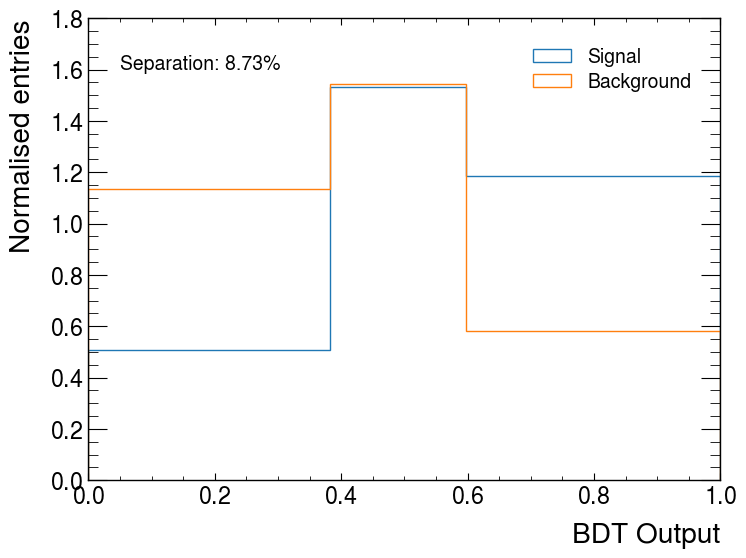

In [22]:

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


In [18]:
# Define the custom formatter function
def custom_formatter(x, pos):
    return f'{x * 0.1:.1f}'

In [8]:
bkg_corr_matrix = df_bkg[feature_cols].corr()
sig_corr_matrix = df_sig[feature_cols].corr()

#bkg_corr_matrix.to_csv('bkg_correlation_matrix.csv', index=True)  # Save to CSV


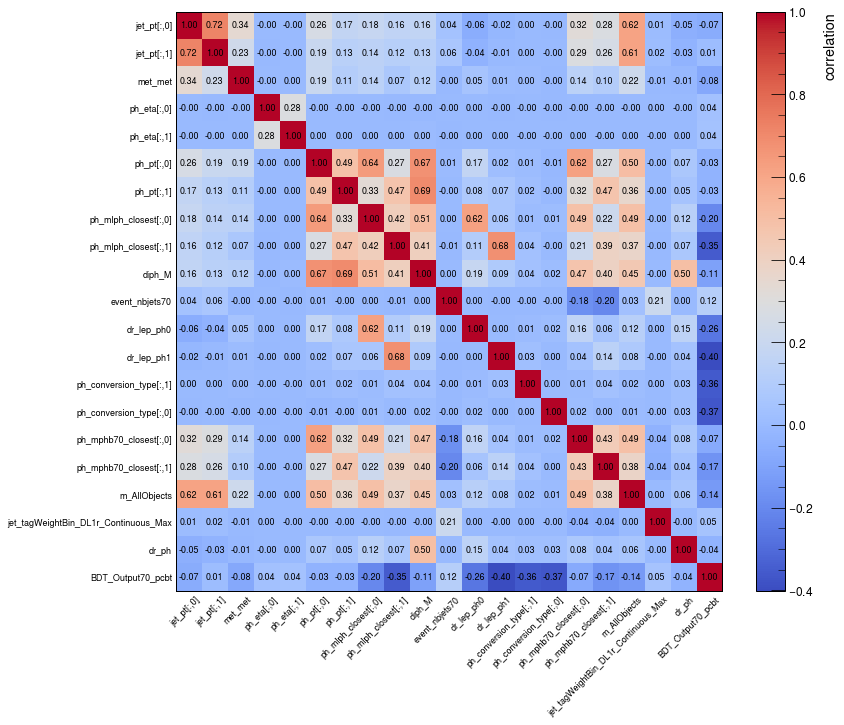

In [9]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = sig_corr_matrix.values  # Assuming sig_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

#plt.savefig('sig_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')


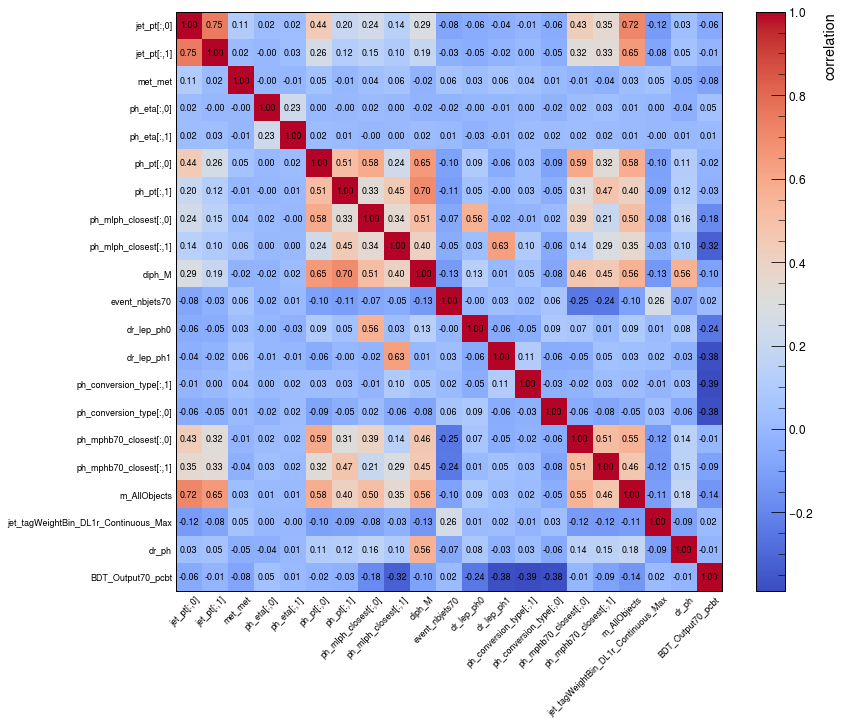

In [10]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = bkg_corr_matrix.values  # Assuming bkg_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides


#plt.savefig('bkg_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')



In [45]:
print(len(corr))

5


In [32]:
xgboost.__version__

'2.0.2'

# Difference of Correlation matrices

In [11]:
corr_diff_matrix = sig_corr_matrix - bkg_corr_matrix

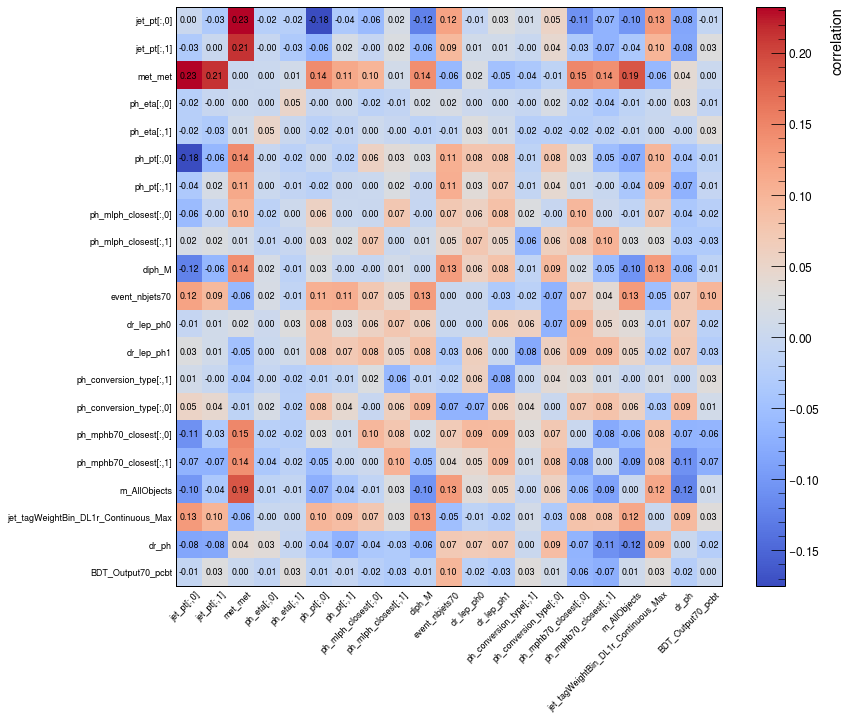

In [14]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = corr_diff_matrix.values  # Assuming bkg_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

plt.savefig('diff_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')


In [17]:
# Set a threshold for significant differences
threshold = 0.1

# Find and print pairs with differences greater than the threshold
significant_diffs = corr_diff_matrix.abs() > threshold
significant_pairs = significant_diffs.stack()[significant_diffs.stack()]
print(significant_pairs)

jet_pt[:,0]                           met_met                                 True
                                      ph_pt[:,0]                              True
                                      diph_M                                  True
                                      event_nbjets70                          True
                                      ph_mphb70_closest[:,0]                  True
                                      m_AllObjects                            True
                                      jet_tagWeightBin_DL1r_Continuous_Max    True
jet_pt[:,1]                           met_met                                 True
met_met                               jet_pt[:,0]                             True
                                      jet_pt[:,1]                             True
                                      ph_pt[:,0]                              True
                                      ph_pt[:,1]                              True
    

# Correlation with DATA (23.01.2025)

In [2]:
Data_path = '/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/Data'

In [4]:
# Feature columns - without BDT output

feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                #'jet_pt[:,2]', 
                #'jet_pt[:,3]',
                #'jet_e[:,0]',
                #'jet_e[:,1]', 
                #'jet_e[:,2]', 
                #'jet_e[:,3]', 
                'met_met',
                # 'met_phi',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                #'ph_e[:,0]', 
                #'ph_e[:,1]', 
                #'ph_phi[:,0]', 
                #'ph_phi[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                #'event_njets',
                #'event_HT', 
                #'event_ST', 
                'event_nbjets70', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb70_closest[:,0]',
                'ph_mphb70_closest[:,1]',
                #'ph_drphb77_leading_pt[:,0]', 
                #'ph_drphb77_leading_pt[:,1]',
                'm_AllObjects',
                #'m_ph_bjet', 
                 #'dr_lep_bjetscore', 
                #'jet_DL1r_bjetscore',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph',
                #'BDT_Output70_pcbt'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


This cell has been run 1 times.


In [5]:
cols = feature_cols+['eventNumber','weight']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [6]:
df_sig = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [21]:
len(df_sig), len(df_bkg)

(323900, 3959)

In [22]:
df_SigBkg = pd.concat([df_sig, df_bkg],ignore_index=False)

In [23]:
len(df_SigBkg)

327859

In [7]:
df_data = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/injected_model6/Data/*data*.root:nominal',expressions=feature_cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [24]:
bkg_corr_matrix = df_bkg[feature_cols].corr()
sig_corr_matrix = df_sig[feature_cols].corr()
data_corr_matrix = df_data[feature_cols].corr()
SigBkg_corr_matrix = df_SigBkg[feature_cols].corr()

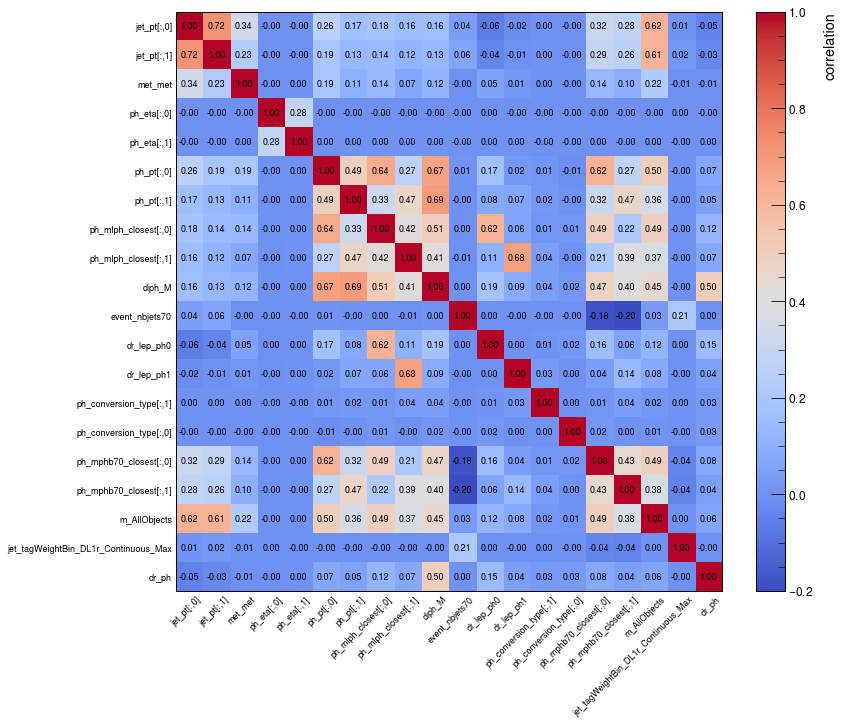

In [20]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = sig_corr_matrix.values  # Assuming sig_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

#plt.savefig('sig_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')


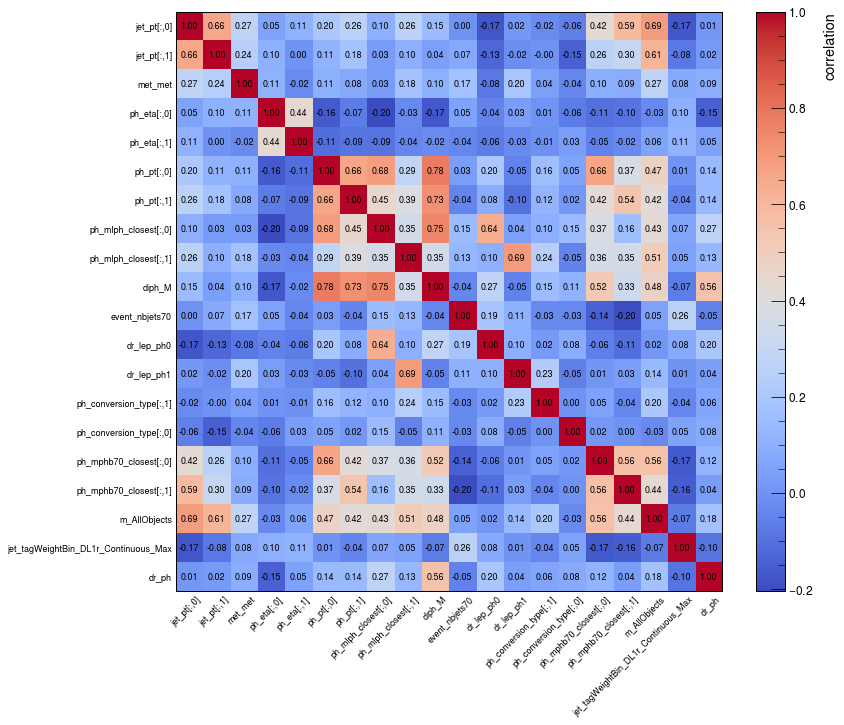

In [23]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = data_corr_matrix.values  # Assuming sig_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

#plt.savefig('sig_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')


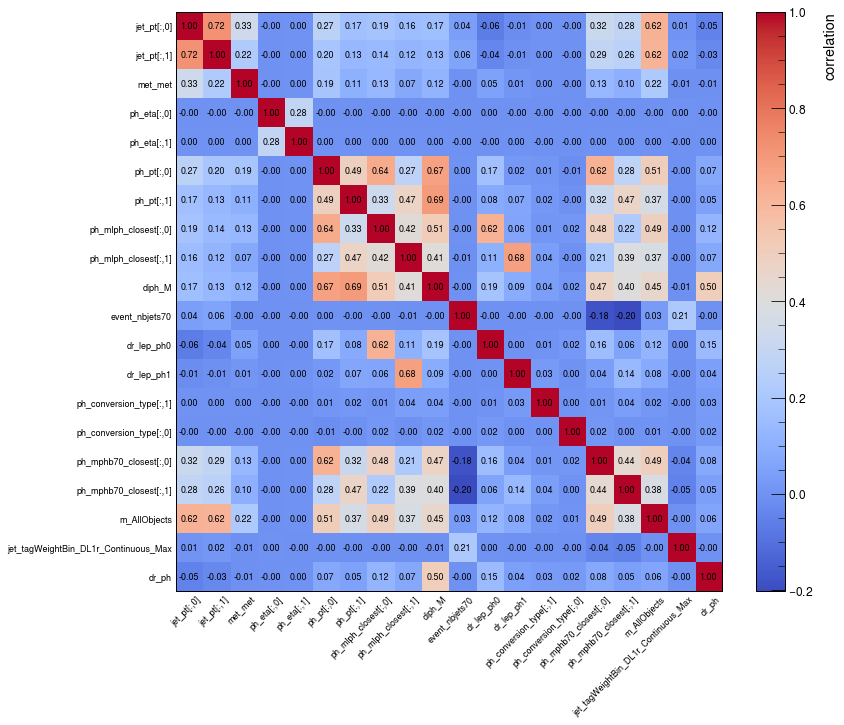

In [25]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = SigBkg_corr_matrix.values  # Assuming sig_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

#plt.savefig('sig_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')


In [9]:
SigData_diff_matrix = sig_corr_matrix - data_corr_matrix

In [20]:
SigBkg_Tot_matrix = sig_corr_matrix + bkg_corr_matrix

In [26]:
SigBkg_Data_diff_matrix = SigBkg_corr_matrix - data_corr_matrix

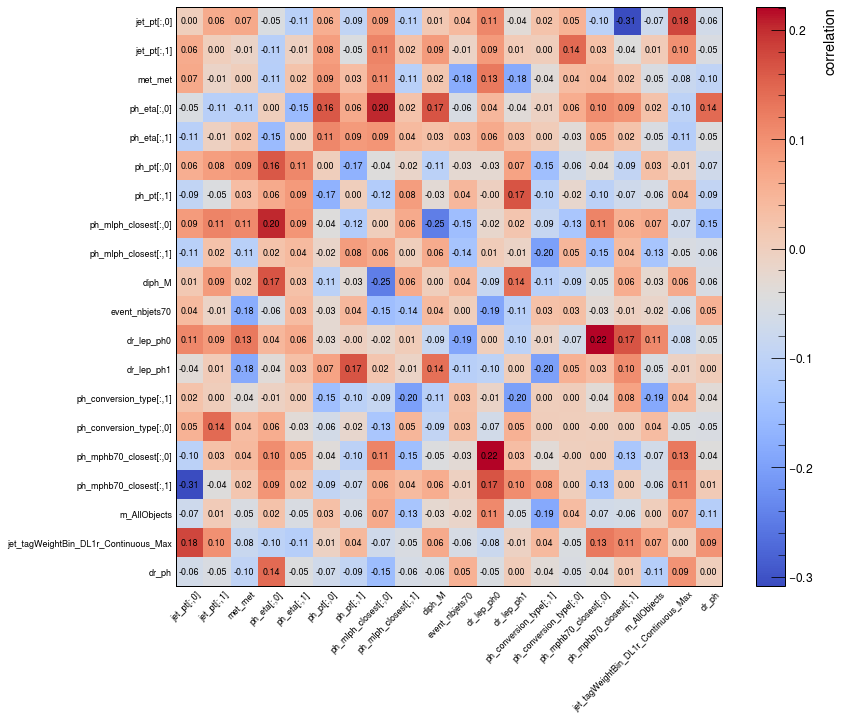

In [27]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = SigData_diff_matrix.values  # Assuming bkg_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

#plt.savefig('diff_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')


In [30]:
BkgData_diff_matrix = bkg_corr_matrix - data_corr_matrix

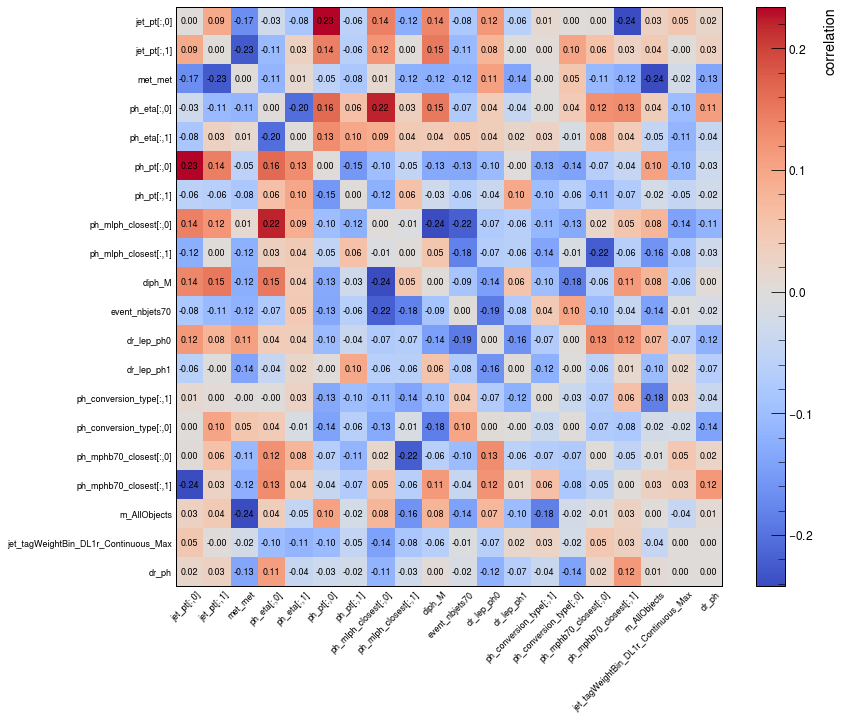

In [31]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = BkgData_diff_matrix.values  # Assuming bkg_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

#plt.savefig('diff_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')


In [17]:
SigBkg_Data_diff_matrix = data_corr_matrix - SigBkg_Tot_matrix 

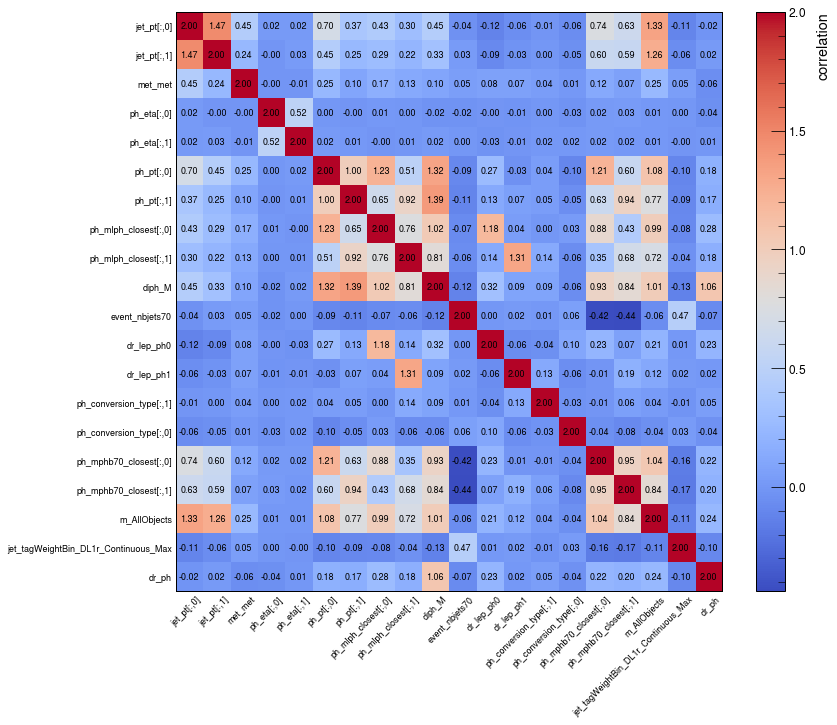

In [19]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = SigBkg_Tot_matrix.values  # Assuming bkg_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

#plt.savefig('diff_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')


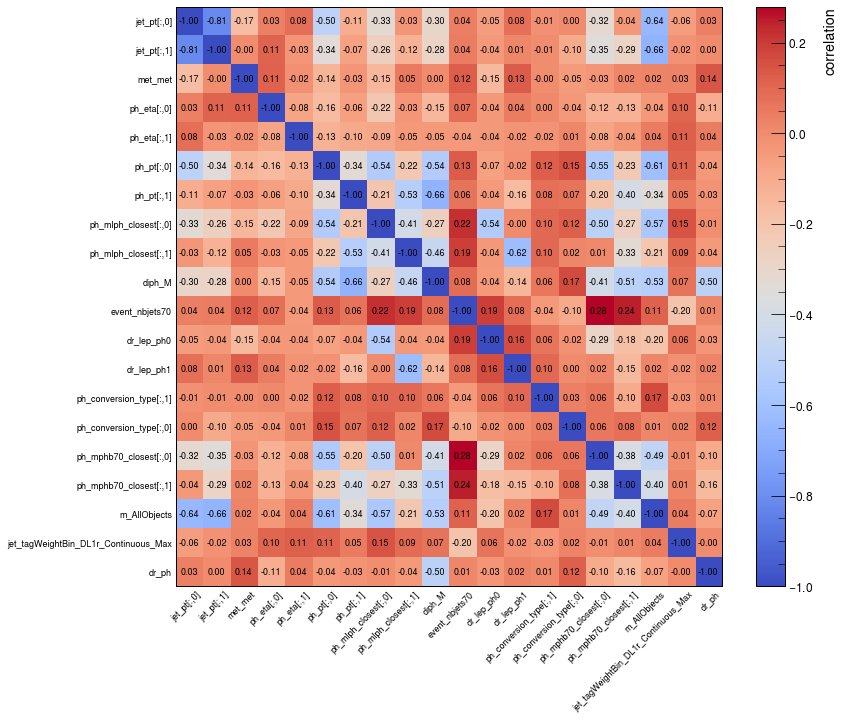

In [18]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = SigBkg_Data_diff_matrix.values  # Assuming bkg_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

#plt.savefig('diff_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')
